In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import (roc_auc_score, precision_score, recall_score, f1_score)
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [2]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
!wget -nc $data

--2026-10-18 12:54:20--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.004s  

2026-10-18 12:54:21 (64.8 MB/s) - ‘course_lead_scoring_2026.csv’ saved [278746/278746]



In [3]:
df = pd.read_csv(data)

In [5]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [6]:
df.shape

(5000, 9)

In [7]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [8]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [9]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']

In [10]:
df[categorical] = df[categorical].fillna('NA')

In [11]:
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

In [12]:
df[numerical] = df[numerical].fillna(0.0)

## Split the Dataset

In [13]:
df_full_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=1
)

df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=1
)

In [14]:
y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

df_train = df_train.drop(columns=['converted'])
df_val = df_val.drop(columns=['converted'])
df_test = df_test.drop(columns=['converted'])

In [15]:
df_train

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score
4740,paid_ads,technology,employed,asia,80198.0,5,9,0.91
1452,paid_ads,retail,employed,asia,50548.0,2,5,0.48
2846,NA,finance,employed,NA,76300.0,0,3,0.42
4670,paid_ads,finance,employed,NA,80371.0,2,6,0.49
168,organic_search,finance,employed,asia,73567.0,2,4,0.48
...,...,...,...,...,...,...,...,...
253,paid_ads,finance,employed,north_america,84573.0,2,3,0.37
1366,events,technology,employed,asia,85051.0,1,3,0.56
753,events,retail,unemployed,asia,21561.0,0,1,0.17
4990,organic_search,healthcare,unemployed,south_america,31691.0,3,5,0.49


In [16]:
df_val

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score
913,social_media,technology,student,south_america,0.0,1,1,0.26
1288,paid_ads,education,employed,north_america,63357.0,4,7,0.73
3551,social_media,healthcare,employed,north_america,72351.0,2,3,0.33
2532,organic_search,technology,student,south_america,41501.0,2,2,0.41
2678,organic_search,education,employed,NA,44817.0,3,7,0.73
...,...,...,...,...,...,...,...,...
924,social_media,healthcare,employed,africa,59325.0,3,6,0.71
3282,social_media,retail,employed,NA,54394.0,1,5,0.46
2067,social_media,healthcare,employed,south_america,51328.0,3,6,0.58
4332,organic_search,retail,unemployed,africa,13315.0,3,5,0.51


In [17]:
df_test

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score
2764,organic_search,healthcare,student,south_america,20241.0,1,3,0.42
4767,organic_search,manufacturing,self_employed,asia,45817.0,2,3,0.41
3814,organic_search,healthcare,employed,north_america,82802.0,3,7,0.69
3499,paid_ads,technology,unemployed,europe,61015.0,1,2,0.19
2735,referral,retail,unemployed,north_america,15154.0,2,2,0.39
...,...,...,...,...,...,...,...,...
448,paid_ads,NA,employed,north_america,79186.0,3,5,0.50
921,NA,education,self_employed,north_america,34582.0,3,7,0.65
4087,social_media,healthcare,unemployed,europe,39573.0,2,1,0.25
1242,referral,technology,employed,north_america,100953.0,2,7,0.70


## ROC AUC

In [18]:
features = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']

for feature in features:
    auc = roc_auc_score(y_train, df_train[feature])

    # Reverse the score if AUC is below 0.5
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[feature])

    print(feature, round(auc, 3))

lead_score 0.788
number_of_courses_viewed 0.723
interaction_count 0.765
annual_income 0.608


## Training the model

In [19]:
# Convert each row into a dictionary
train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')

# One-hot encode categorical features
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

In [20]:
model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000
)

model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [21]:
# Calculate the predicted probability of conversion
y_pred_proba = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred_proba)

print("Validation ROC AUC:", round(auc, 3))

Validation ROC AUC: 0.732


## Precision & Recall

In [22]:
thresholds = np.arange(0.0, 1.01, 0.01)

precisions = []
recalls = []

for threshold in thresholds:

    # Convert probabilities into binary predictions
    y_pred = (y_pred_proba >= threshold).astype(int)

    precision = precision_score(
        y_val, y_pred, zero_division=0
    )

    recall = recall_score(
        y_val, y_pred, zero_division=0
    )

    precisions.append(precision)
    recalls.append(recall)

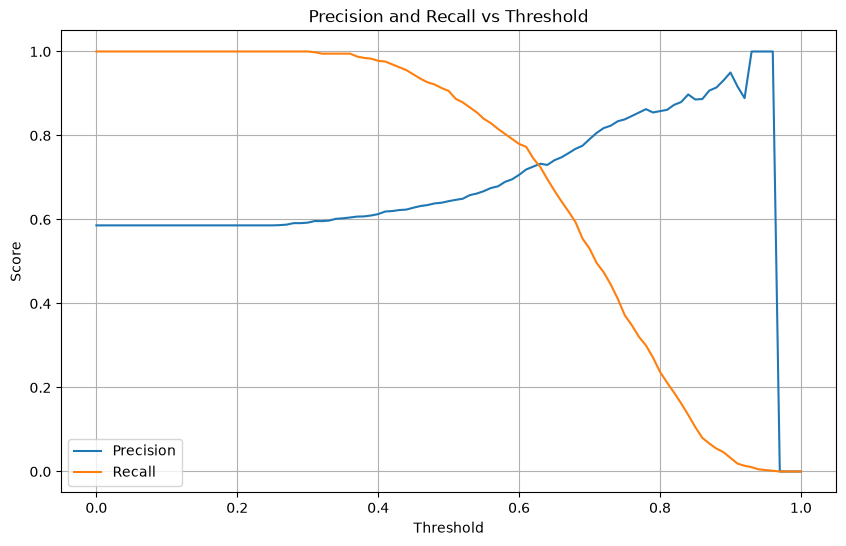

In [23]:
# Plot both curves
plt.figure(figsize=(10, 6))

plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid(True)

plt.show()

In [24]:
results = pd.DataFrame({
    'threshold': thresholds,
    'precision': precisions,
    'recall': recalls
})

# Ignore thresholds where both metrics are zero
results = results[
    (results['precision'] != 0) |
    (results['recall'] != 0)
].copy()

results['difference'] = abs(
    results['precision'] - results['recall']
)

results.sort_values('difference').head(10)

,threshold,precision,recall,difference
63,0.63,0.732759,0.725256,0.007503
62,0.62,0.725914,0.745734,0.019820
64,0.64,0.729875,0.696246,0.033629
61,0.61,0.719048,0.773038,0.053990
65,0.65,0.741021,0.668942,0.072079
60,0.60,0.706337,0.779863,0.073527
59,0.59,0.695652,0.791809,0.096157
66,0.66,0.748016,0.643345,0.104671
58,0.58,0.689605,0.803754,0.114150
57,0.57,0.678977,0.815700,0.136722


## Find the Threshold with the highest F1 Score

In [25]:
f1_scores = []

for precision, recall in zip(precisions, recalls):

    if precision + recall == 0:
        f1 = 0.0
    else:
        f1 = (2 * precision * recall / (precision + recall))

    f1_scores.append(f1)

In [26]:
best_index = np.argmax(f1_scores)

print("Best threshold:", thresholds[best_index])
print("Maximum F1 score:", round(f1_scores[best_index], 3))

Best threshold: 0.41000000000000003
Maximum F1 score: 0.758


In [27]:
# Display the top results
f1_results = pd.DataFrame({
    'threshold': thresholds,
    'f1_score': f1_scores
})

f1_results.sort_values(
    'f1_score',
    ascending=False
).head(10)

,threshold,f1_score
41,0.41,0.757616
42,0.42,0.756325
43,0.43,0.756032
45,0.45,0.754768
44,0.44,0.754717
46,0.46,0.754301
48,0.48,0.754190
40,0.40,0.753452
47,0.47,0.753121
50,0.50,0.752658


## 5-fold Cross-Validation

In [30]:
def train_and_evaluate_auc(train_df, val_df):

    # Separate the target from the input features
    y_train_fold = train_df['converted'].values
    y_val_fold = val_df['converted'].values

    X_train_fold = train_df.drop(columns=['converted'])
    X_val_fold = val_df.drop(columns=['converted'])

    # Convert rows into dictionaries
    train_dicts = X_train_fold.to_dict(orient='records')
    val_dicts = X_val_fold.to_dict(orient='records')

    # Encode features using the training fold
    dv = DictVectorizer(sparse=False)

    X_train_encoded = dv.fit_transform(train_dicts)
    X_val_encoded = dv.transform(val_dicts)

    # Train logistic regression
    model = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000
    )

    model.fit(X_train_encoded, y_train_fold)

    # Predict probabilities for the positive class
    y_pred_proba = model.predict_proba(X_val_encoded)[:, 1]

    # Calculate ROC AUC
    return roc_auc_score(y_val_fold, y_pred_proba)

In [31]:
# Perform the 5-fold
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):

    # Create the training and validation folds
    train_fold = df_full_train.iloc[train_idx]
    val_fold = df_full_train.iloc[val_idx]

    # Train and evaluate the model
    auc = train_and_evaluate_auc(train_fold, val_fold)

    scores.append(auc)

    print("AUC:", round(auc, 3))

AUC: 0.731
AUC: 0.73
AUC: 0.736
AUC: 0.741
AUC: 0.721


In [32]:
# Calculate Standard Deviation
print("Scores:", scores)
print("Mean AUC:", round(np.mean(scores), 3))
print("Standard deviation:", round(np.std(scores), 3))

Scores: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
Mean AUC: 0.732
Standard deviation: 0.007


# Hyperparameter Tuning

In [33]:
C_values = [0.000001, 0.001, 1]

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

cv_results = []

for C in C_values:

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):

        train_fold = df_full_train.iloc[train_idx]
        val_fold = df_full_train.iloc[val_idx]

        # Separate target and features
        y_train_fold = train_fold['converted'].values
        y_val_fold = val_fold['converted'].values

        X_train_fold = train_fold.drop(columns=['converted'])
        X_val_fold = val_fold.drop(columns=['converted'])

        # One-hot encode categorical variables
        dv = DictVectorizer(sparse=False)

        X_train_encoded = dv.fit_transform(
            X_train_fold.to_dict(orient='records')
        )

        X_val_encoded = dv.transform(
            X_val_fold.to_dict(orient='records')
        )

        # Train model using the current C
        model = LogisticRegression(
            solver='liblinear',
            C=C,
            max_iter=1000
        )

        model.fit(X_train_encoded, y_train_fold)

        # Calculate ROC AUC on the validation fold
        y_pred_proba = model.predict_proba(
            X_val_encoded
        )[:, 1]

        auc = roc_auc_score(y_val_fold, y_pred_proba)

        scores.append(auc)

    mean_auc = np.mean(scores)
    std_auc = np.std(scores)

    cv_results.append({
        'C': C,
        'mean_auc': mean_auc,
        'std_auc': std_auc
    })

    print(
        f"C={C}: "
        f"mean AUC={mean_auc:.3f}, "
        f"std={std_auc:.3f}"
    )

C=1e-06: mean AUC=0.617, std=0.019
C=0.001: mean AUC=0.749, std=0.010
C=1: mean AUC=0.732, std=0.007


In [34]:
# Display the comparison
cv_results_df = pd.DataFrame(cv_results)

cv_results_df.sort_values(
    'mean_auc',
    ascending=False
)

,C,mean_auc,std_auc
1,0.001000,0.749172,0.009996
2,1.000000,0.731727,0.006853
0,0.000001,0.616734,0.018670
